In [ ]:
# Hosted D2L setup: fetch the exact helper module used to build this notebook.
from pathlib import Path
from urllib.request import urlretrieve
from importlib.metadata import PackageNotFoundError, version
import importlib.util, os, subprocess, sys

required = ['numpy', 'pandas', 'matplotlib', 'requests', 'scipy', 'pillow', 'regex', 'torch', 'torchvision']
imports = {'pillow': 'PIL'}
pinned = {}
fallbacks = {'torch': 'torch==2.11.0', 'torchvision': 'torchvision==0.26.0'}
device = os.environ.get("D2L_HOSTED_DEVICE", "auto").lower()
if device not in ("auto", "cpu", "gpu"):
    raise ValueError(f"Invalid D2L_HOSTED_DEVICE={device!r}")
if device == "auto":
    try:
        gpu = (Path("/dev/nvidia0").exists() or
               subprocess.run(["nvidia-smi", "-L"], capture_output=True,
                              timeout=5).returncode == 0)
    except (FileNotFoundError, subprocess.SubprocessError):
        gpu = False
else:
    gpu = device == "gpu"
if not gpu:
    os.environ.setdefault("CUDA_VISIBLE_DEVICES", "-1")
    os.environ.setdefault("JAX_PLATFORMS", "cpu")
tensorflow_version = None
if 'pytorch' in ("tensorflow", "jax"):
    try:
        tensorflow_version = version("tensorflow")
    except PackageNotFoundError:
        pass
# Colab's CPU image currently carries a CUDA-enabled TensorFlow wheel. Its
# first ordinary tensor operation probes CUDA and emits an error-level cuInit
# diagnostic. JAX notebooks also use TensorFlow for data loading, so overlay
# the matching CPU build in both CPU variants. Keep the provider's
# ``tensorflow`` distribution metadata: other preinstalled Colab packages
# depend on that distribution name, while both wheels expose the same module.
if not gpu and 'pytorch' in ("tensorflow", "jax"):
    try:
        tensorflow_cpu_version = version("tensorflow-cpu")
    except PackageNotFoundError:
        tensorflow_cpu_version = None
    if (tensorflow_version is not None and
            tensorflow_cpu_version != tensorflow_version):
        subprocess.check_call([
            sys.executable, "-m", "pip", "install", "-q", "--no-deps",
            f"tensorflow-cpu=={tensorflow_version}",
        ])
if "tf-keras" in fallbacks and tensorflow_version is not None:
    fallbacks["tf-keras"] = f"tf-keras=={tensorflow_version}"
missing = []
for package in required:
    if package in pinned:
        wanted, cpu_requirement, gpu_requirement, match = pinned[package]
        requirement = gpu_requirement if gpu else cpu_requirement
        try:
            installed = version(package)
        except PackageNotFoundError:
            installed = None
        actual = (installed.split("+", 1)[0]
                  if installed is not None and match == "public" else installed)
        if actual != wanted:
            missing.append(requirement)
    elif importlib.util.find_spec(imports.get(package, package)) is None:
        missing.append(fallbacks.get(package, package))
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

mismatched = []
for package, (wanted, _, _, match) in pinned.items():
    try:
        installed = version(package)
    except PackageNotFoundError:
        installed = None
    actual = (installed.split("+", 1)[0]
              if installed is not None and match == "public" else installed)
    if actual != wanted:
        mismatched.append(f"{package}={installed!r} (expected {wanted})")
if mismatched:
    raise RuntimeError("Hosted runtime setup failed: " + ", ".join(mismatched))

root = Path(".d2l-hosted") / "8a5255b0fce49fc730baae6ea6ecc601d45bb16b"
package = root / "d2l"
package.mkdir(parents=True, exist_ok=True)
base = "https://raw.githubusercontent.com/smolix/d2l-neu/8a5255b0fce49fc730baae6ea6ecc601d45bb16b/d2l"
for name in ('__init__.py', 'torch.py'):
    target = package / name
    if not target.exists():
        urlretrieve(f"{base}/{name}", target)
if str(root.resolve()) not in sys.path:
    sys.path.insert(0, str(root.resolve()))
pythonpath = os.environ.get("PYTHONPATH", "").split(os.pathsep)
if str(root.resolve()) not in pythonpath:
    os.environ["PYTHONPATH"] = os.pathsep.join(
        [str(root.resolve()), *[entry for entry in pythonpath if entry]]
    )


# Modern Training Recipes for Convnets

So far in this chapter, the networks of each section were trained under one
shared procedure, so that differences in accuracy could be credited to the
architectures. Published comparisons are often made differently: a new
architecture is trained with the latest methods and compared with a baseline
trained years earlier. How much of a reported accuracy comes from the
*training recipe* (the optimizer, schedule, augmentation, regularization, and
length of training) rather than from the network itself?

ResNet-50, the deeper relative of the ResNet-18 of that section,
gives a clear answer. @wightman2021resnet changed nothing about its
architecture and trained it with the methods in use around 2022 instead of
those of its 2015 debut. Its ImageNet top-1 accuracy rose from 76.1% to
80.4%. That gain, from the recipe alone, is as large as the gains that many
new architectures of those years reported over ResNet-50. If an architecture
paper reports a gain of two points over a baseline trained with an older
recipe, the gain may therefore come from the recipe, not the architecture.
The same study makes this point by retraining the unchanged ResNet-50 to the
accuracy of several of its successors. This section lists what changed
between 2015 and 2022, implements each ingredient in a few lines, and then
trains one ResNet-18 under an old and a new recipe to measure the difference.

In [ ]:
import math
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from d2l import torch as d2l

In [ ]:
import random

## Training Recipes from 2015 to 2022

The original ResNet recipe was already careful: stochastic gradient descent
with momentum, weight decay, a learning rate divided by 10 twice during
training, and random crops and horizontal flips as augmentation
[@He.Zhang.Ren.ea.2016]. Between then and about 2022, each of these
choices was revisited. The first systematic accounting, in 2019, collected
the techniques that had accumulated (warmup, cosine decay, label smoothing,
Mixup, zero-initializing the last batch-normalization scale in each block,
knowledge distillation) and showed that together with tweaks to the network
they lift ResNet-50 from 75.3% to 79.3% [@He.Zhang.Zhang.ea.2019]. One
tweak, *ResNet-D*, changes the downsampling blocks: their stride moves from
the first $1 \times 1$ convolution of the branch to the $3 \times 3$ one, and
their shortcut average-pools before its $1 \times 1$ convolution, which with
stride 2 would read only one of every four positions (that section).
The "ResNet strikes back" study [@wightman2021resnet] then kept the
architecture fixed and trained the unmodified ResNet-50 with three procedures
of increasing cost: A3 (100 epochs) reaches 78.1%, A2 (300 epochs) 79.8%, and
A1 (600 epochs, the LAMB optimizer, a binary cross-entropy loss, and heavy
augmentation) 80.4%. the table summarizes the shift.

:A 2015 ImageNet recipe and a representative high-accuracy recipe from the
early 2020s. The later column is not a universal standard; strong recipes still
vary by model and compute budget.

| Ingredient | 2015 recipe | 2022 recipe |
|:--|:--|:--|
| Optimizer | SGD with momentum | AdamW or LAMB; tuned SGD remains competitive |
| Schedule | step decay (divide by 10 twice) | cosine decay with linear warmup |
| Augmentation | random crops, horizontal flips | RandAugment, Mixup, CutMix, random erasing |
| Regularization | weight decay | + label smoothing, stochastic depth |
| Duration | 90 epochs | 300 to 600 epochs |
| Evaluated weights | final weights | exponential moving average of the weights |

The *optimizer* row records a common change, not a universal one. Earlier
implementations of Adam added weight decay to the gradient, where Adam's
per-coordinate rescaling distorts it. AdamW [@Loshchilov.Hutter.2019]
applies the decay to the weights directly, outside the rescaling, and made
adaptive methods competitive with tuned SGD on many vision tasks. At batch
sizes in the tens of thousands, rescaling the update of each layer by the
size of its weights keeps training stable, as in LARS
[@You.Gitman.Ginsburg.2017] and its Adam-based relative LAMB, which
recipe A1 above uses.

The *schedule* row replaces the drops by a smooth cosine decay
[@Loshchilov.Hutter.2016], preceded by a few epochs of linear warmup. The
*augmentation* and *regularization* rows account for much of the gain.
RandAugment [@cubuk2020randaugment] applies randomly chosen image
transformations at a single tuned strength; Mixup [@zhang2018mixup] and
CutMix [@yun2019cutmix] blend pairs of training images and their labels;
label smoothing [@Szegedy.Vanhoucke.Ioffe.ea.2016] softens the targets;
stochastic depth [@huang2016stochasticdepth] randomly skips whole residual
blocks during training. Each of these makes the training task harder, so the
network needs more epochs to fit it, and the *duration* row grows from 90
epochs to several hundred. Regularization and duration have to grow together:
the short A3 recipe above uses weaker augmentation than the long A1 recipe,
because a heavily regularized short run can do worse than a lightly regularized
one. The last row changes which weights are evaluated: instead of the final
weights of a noisy optimization, modern recipes evaluate a running average of
the weights.

## Implementing the Ingredients

Each ingredient takes a few lines of code. We implement label smoothing, the
cosine schedule, Mixup, stochastic depth, and the weight average.
RandAugment is a library call in practice, and its contribution lies in the
tuning of the augmentation strength rather than in the code, so we omit it.

### Label Smoothing

With one-hot targets, the cross-entropy loss of a correctly classified
example keeps decreasing as the logit of the correct class grows, so the
loss can never reach its minimum with finite logits and the network is
rewarded for ever larger confidence. Label smoothing replaces the one-hot
target by a mixture that puts weight $1-\epsilon$ on the label and spreads
$\epsilon$ uniformly over all $K$ classes. Writing $p_k$ for the predicted
softmax probabilities, the loss on an example with label $y$ becomes

$$
l_\epsilon = -(1-\epsilon) \log p_y - \frac{\epsilon}{K} \sum_{k=1}^K \log p_k.
$$

The first term is the ordinary cross-entropy, weighted by $1-\epsilon$; the
second penalizes any class whose probability approaches zero. The loss is
minimized by the probabilities $1-\epsilon+\epsilon/K$ on the correct class
and $\epsilon/K$ on every other class, which a finite gap between the logits
attains. For a prediction that is already very confident and correct, the
unsmoothed loss is nearly zero, while the smoothed loss stays well above
zero:

In [2]:
logits, y = d2l.tensor([[10.0, 0.0, 0.0]]), d2l.tensor([0])
for epsilon in (0.0, 0.1):
    loss = F.cross_entropy(logits, y, label_smoothing=epsilon)
    print(f'epsilon={epsilon}: loss={float(loss):.4f}')

epsilon=0.0: loss=0.0001
epsilon=0.1: loss=0.6668


With $\epsilon = 0.1$ the loss of this example is 0.67 instead of 0.0001, so
the optimizer stops pushing confident examples further and spends its effort
on the others.

### Cosine Schedules with Warmup

A step schedule holds the learning rate constant for tens of epochs and then
divides it by 10, an abrupt change whose two times are extra
hyperparameters. The modern default is the schedule with which we have
trained the networks of this chapter since AlexNet (that section): a
linear *warmup* from zero to the base rate $\eta_0$ over the first
$t_\textrm{w}$ steps, then the half-cosine *decay* the equation
to zero at the last step $T$.
Warmup exists because a freshly
initialized network can produce large, badly scaled gradients, and a few
steps at small rates let the running statistics of batch normalization and
of the optimizer settle before full-size updates arrive. The long tail of
small rates lets the noisy iterates settle into a region of low loss, and
there is no time of a drop to tune. The function `d2l.cosine_warmup(t,
num_steps, warmup_steps)` of that section returns the factor by
which the schedule multiplies the base rate at step $t$; the optimizer
updates the rate after every minibatch. We plot it next to the step decay of
the 2015 recipe, each over the budget it gets in the experiment later in
this section: 30 epochs for the step decay, to which the experiment adds a
two-epoch warmup, and 45 for the cosine, with 79 minibatches per epoch.

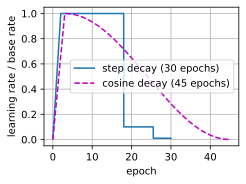

In [3]:
def step_decay(t, num_steps, warmup_steps):
    """Recipe A: linear warmup, then divide by 10 at 60% and 85% of steps."""
    warmup = min((t + 1) / warmup_steps, 1)
    return warmup * 0.1 ** sum(t >= int(f * num_steps) for f in (0.6, 0.85))

steps_per_epoch = 79
steps_a = list(range(30 * steps_per_epoch))  # Recipe A: 30 epochs
steps_b = list(range(45 * steps_per_epoch))  # Recipe B: 45 epochs
d2l.plot([[t / steps_per_epoch for t in steps_a],
          [t / steps_per_epoch for t in steps_b]],
         [[step_decay(t, len(steps_a), 2 * steps_per_epoch) for t in steps_a],
          [float(d2l.cosine_warmup(t, len(steps_b), 3 * steps_per_epoch))
           for t in steps_b]],
         xlabel='epoch', ylabel='learning rate / base rate',
         legend=['step decay (30 epochs)', 'cosine decay (45 epochs)'])

The cell below builds recipe B's schedule for a base rate of 0.002 and prints
the rate at the first step, at the end of warmup, halfway through the decay,
and at the last step.

`LambdaLR` multiplies the base rate of the optimizer by a function of the
step. Calling `scheduler.step()` after every optimizer step advances it by
one minibatch.

In [4]:
T, t_w = 45 * 79, 3 * 79
optim = torch.optim.SGD([nn.Parameter(torch.zeros(1))], lr=2e-3)
scheduler = torch.optim.lr_scheduler.LambdaLR(
    optim, lambda t: d2l.cosine_warmup(t, T, t_w))
rates = []
for t in range(T):  # One optimizer step and one scheduler step per minibatch
    rates.append(scheduler.get_last_lr()[0])
    optim.step()
    scheduler.step()
[round(rates[t], 6) for t in (0, t_w, (T + t_w) // 2, T - 1)]

[0.0, 0.002, 0.001, 0.0]

The rates are 0, 0.002, 0.001, and nearly 0, as the formula predicts.

### Mixup

Mixup [@zhang2018mixup] trains on convex combinations of pairs of
examples. For each minibatch it draws a mixing weight
$\lambda \sim \mathrm{Beta}(\alpha, \alpha)$ and a random partner $j$ for
every example $i$, and trains on

$$
\tilde{\mathbf{x}} = \lambda \mathbf{x}_i + (1-\lambda) \mathbf{x}_j, \qquad
\tilde{\mathbf{y}} = \lambda \mathbf{y}_i + (1-\lambda) \mathbf{y}_j,
$$

where $\mathbf{y}_i$ and $\mathbf{y}_j$ are one-hot label vectors, so the
mixed label $\tilde{\mathbf{y}}$ is a distribution over classes. The
cross-entropy is linear in the target distribution, so the loss on
$\tilde{\mathbf{y}}$ equals the $\lambda$-weighted sum of the losses on the
two original labels, and we implement it that way. Mixup asks the network to
behave linearly between training examples, which discourages it from
memorizing individual examples. With the usual small $\alpha$ (0.1 to 0.2),
the Beta distribution puts most of its mass near 0 and 1, so most minibatches
are barely mixed and a few are blended strongly. The function below mixes a
minibatch with one $\lambda$ for all of it. We save it in the `d2l` package
because the ConvNeXt section reuses it.

In [5]:
def mixup(X, y, alpha):
    """Mix a minibatch with a shuffled copy; return both label sets."""
    lam = random.betavariate(alpha, alpha)
    perm = torch.randperm(X.shape[0], device=X.device)
    return lam * X + (1 - lam) * X[perm], y, y[perm], lam

To see the blending, we mix a minibatch of Fashion-MNIST images with
$\alpha = 2$, which favors values of $\lambda$ near the middle of its range
(training uses a much smaller $\alpha$). The top row shows the originals,
the bottom row their mixtures; the printed $\lambda$ is drawn afresh in
every run.

lambda = 0.50


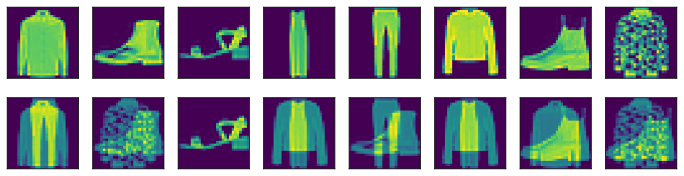

In [6]:
data = d2l.FashionMNIST(batch_size=8)
X, y = next(iter(data.train_dataloader()))
X_mix, y_a, y_b, lam = mixup(X, y, alpha=2.0)
d2l.show_images(torch.cat([X, X_mix]).squeeze(1), 2, 8)
print(f'lambda = {lam:.2f}')

CutMix [@yun2019cutmix] mixes in space instead: it cuts a rectangle
from one image and pastes it into the other, and mixes the labels in
proportion to the area. Every pixel then comes from a real image, and modern
recipes alternate randomly between Mixup and CutMix from one minibatch to the
next. The exercises implement it.

### Stochastic Depth

Dropout (that section) sets randomly chosen activations to zero
during training. Stochastic depth [@huang2016stochasticdepth] applies
the same idea to whole residual branches: during training, the branch of
each residual block is dropped with probability $p$, so the block passes its
input through unchanged and the step trains a shallower network. Residual
connections make this safe, since the identity path always carries the
signal. For a block that computes $\mathbf{x} + f(\mathbf{x})$, the branch
becomes

$$
\mathbf{x} + \frac{b}{1 - p} f(\mathbf{x}), \qquad b \sim \mathrm{Bernoulli}(1-p).
$$

The expected value of $b/(1-p)$ is 1, so the expected output of the branch is
unchanged, and at evaluation time the block runs without dropping, as with
inverted dropout. Modern implementations draw $b$ separately for every
example in the minibatch. The function `drop_path` does this, and we save it
for the ConvNeXt section. The block below subclasses the `Residual` block of
that section (in the residual block the final ReLU follows the
addition) and drops its branch before the addition. Running 1,000 examples
through it in training mode, the fraction of examples whose output equals
the ReLU of the input, the ones whose branch was dropped, should be close to
$p$.

In [7]:
def drop_path(Y, p, training):
    """Zero each example of Y with probability p, rescale the rest."""
    if not training or p == 0:
        return Y
    shape = (Y.shape[0],) + (1,) * (Y.ndim - 1)  # One draw per example
    keep = torch.rand(shape, device=Y.device) > p
    return Y * keep / (1 - p)

class StochasticResidual(d2l.Residual):
    """A residual block whose branch is dropped with probability p."""
    def __init__(self, num_channels, p):
        super().__init__(num_channels)
        self.p = p

    def forward(self, X):
        Y = self.bn2(self.conv2(F.relu(self.bn1(self.conv1(X)))))
        return F.relu(X + drop_path(Y, self.p, self.training))

blk, X = StochasticResidual(3, p=0.5), torch.randn(1000, 3, 8, 8)
Y = blk(X)  # A module is in training mode until .eval() is called
dropped = (Y == F.relu(X)).flatten(1).all(1).float().mean()
print(f'fraction of examples with a dropped branch: {float(dropped):.3f}')

fraction of examples with a dropped branch: 0.518


In deep networks the drop probability usually grows linearly from 0 in the
first block to a maximum between 0.1 and 0.5 in the last. The per-example
implementation computes every branch before masking it, so it regularizes
but saves no arithmetic. The original method draws one $b$ per block and
minibatch and can skip a dropped branch entirely, which shortens training.

### Averaging Weights

The last row of the table costs almost nothing.
Late in training, stochastic gradients make the parameters fluctuate around
a region of low loss, and an average of recent parameters lies closer to the
middle of that region than any single one. Stochastic weight averaging
[@Izmailov.Podoprikhin.Garipov.ea.2018] takes an equal-weight average of
iterates late in training. Modern recipes more often keep an exponential
average: a *shadow copy* $\bar{\theta}$ of the parameters into which, after
every update, the current ones are blended:

$$
\bar{\theta} \leftarrow \beta \bar{\theta} + (1-\beta) \theta.
$$

This is an *exponential moving average* (EMA): the parameters of $k$ steps ago
enter $\bar{\theta}$ with weight $(1-\beta)\beta^k$, so the average reaches
back about $1/(1-\beta)$ steps, 100 steps for $\beta = 0.99$. Training updates
$\theta$ as usual; only evaluation uses $\bar{\theta}$. The class below is the
whole mechanism. It averages the trainable parameters; the running statistics
of batch normalization are not parameters, and the exercises ask which
statistics the averaged network should use. We apply it to a one-weight model
whose weight we set to noisy values around 1, as stochastic gradient steps
would.

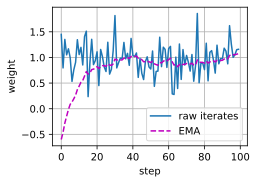

In [8]:
class EMA:
    """A shadow copy of a model's parameters, updated after each step."""
    def __init__(self, model, decay=0.99):
        self.decay = decay
        self.shadow = {k: p.detach().clone()
                       for k, p in model.named_parameters()}

    @torch.no_grad()
    def update(self, model):
        for k, p in model.named_parameters():
            self.shadow[k].lerp_(p, 1 - self.decay)  # beta*avg + (1-beta)*p

net = nn.Linear(1, 1, bias=False)
ema, raw, avg = EMA(net, decay=0.9), [], []
for t in range(100):  # Noisy iterates around 1.0
    with torch.no_grad():
        net.weight.copy_(1 + 0.3 * torch.randn(1, 1))
    ema.update(net)
    raw.append(float(net.weight.detach()))
    avg.append(float(ema.shadow['weight']))
d2l.plot(list(range(100)), [raw, avg], xlabel='step', ylabel='weight',
         legend=['raw iterates', 'EMA'])

With $\beta = 0.9$ the average reaches back about 10 steps: it fluctuates
far less than the iterates and follows their mean. The same horizon is the
risk of the method. If $1/(1-\beta)$ steps is long compared with the time
over which the weights are still improving, the average lags behind them
and evaluates worse than the final weights. Recipes therefore choose
$\beta$ close to 1 (0.999 or 0.9999) only for long runs.

## Controlled Comparison on One Network

We now combine the ingredients and measure what they add. The network is the
ResNet-18 of that section: a $7 \times 7$ convolution with stride 2
and a $3 \times 3$ max-pooling, four stages of two residual blocks with 64,
128, 256, and 512 channels, global average pooling, and a linear layer. We
rebuild it from the library's `Residual` block and initialize all convolution
and linear weights with the He initialization of
that section, normal with variance $2/n_\textrm{in}$. As
in that section, the convolutions have no bias, and the bias of the
linear layer starts at zero. The task is Fashion-MNIST at $96 \times 96$, with
one change: we train on a random subset of 10,000 of the 60,000 training
images. With less data, regularization matters more, and the experiment stays
small enough to rerun. Each run draws its own subset, and both recipes of a
run share it. Each recipe takes the base rate `lr` and the total number of
optimizer steps `num_steps`, from which its schedule is computed.

In [9]:
class FashionMNIST10k(d2l.FashionMNIST):
    """Fashion-MNIST with a random subset of num_train training images."""
    def __init__(self, batch_size=128, resize=(96, 96), num_train=10000):
        super().__init__(batch_size, resize)
        idx = torch.randperm(len(self.train))[:num_train]
        self.train = torch.utils.data.Subset(self.train, idx)

class ResNet18(d2l.Classifier):
    """The ResNet-18 of the residual-networks section, from d2l.Residual."""
    def __init__(self, lr, num_steps, num_classes=10):
        super().__init__()
        self.save_hyperparameters()
        layers = [nn.LazyConv2d(64, kernel_size=7, stride=2, padding=3,
                                bias=False),
                  nn.LazyBatchNorm2d(), nn.ReLU(),
                  nn.MaxPool2d(kernel_size=3, stride=2, padding=1)]
        for i, c in enumerate((64, 128, 256, 512)):
            for j in range(2):
                down = i > 0 and j == 0
                layers.append(d2l.Residual(c, use_1x1conv=down,
                                           strides=2 if down else 1))
        layers += [nn.AdaptiveAvgPool2d((1, 1)), nn.Flatten(),
                   nn.LazyLinear(num_classes)]
        self.net = nn.Sequential(*layers)

    def weight_init(self, module):  # The Trainer applies it after a dry run
        if isinstance(module, (nn.Conv2d, nn.Linear)):
            nn.init.kaiming_normal_(module.weight)  # Variance 2/n_in
            if module.bias is not None:
                nn.init.zeros_(module.bias)

The two recipes differ only in their optimizers, schedules, and training
losses. *Recipe A* follows 2015: SGD with momentum 0.9, weight decay
$5 \times 10^{-4}$ added to the gradient, a base rate of 0.05 reached by a
linear warmup over the first two epochs and divided by 10 at 60% and at 85% of
the steps, the plain cross-entropy loss, and 30 epochs. Without the warmup,
this rate makes the loss diverge in the first epoch in about a third of the
runs. A short warmup is the standard remedy for large rates with batch
normalization; @He.Zhang.Ren.ea.2016 used one for their deepest
ResNet, and @Goyal.Dollar.Girshick.ea.2017 made it routine. The
*compact modern recipe* B uses AdamW with weight decay 0.05, a base rate of
0.002 with three epochs of warmup and a cosine decay, label smoothing with
$\epsilon = 0.1$, Mixup with $\alpha = 0.2$, and 45 epochs, since longer
training is part of the recipe. It omits RandAugment, CutMix, stochastic
depth, and weight averaging to keep the experiment small, so its result
measures this subset of the full recipe. Both recipes report the plain
cross-entropy as validation loss; label smoothing and Mixup change only the
training loss.

In [10]:
class ClassicRecipe(ResNet18):
    """Recipe A: SGD with momentum, weight decay, warmup, step decay."""
    def configure_optimizers(self):
        optim = torch.optim.SGD(self.parameters(), lr=self.lr, momentum=0.9,
                                weight_decay=5e-4)
        warmup = 2 * self.num_steps // 30  # Two of the 30 epochs
        return optim, torch.optim.lr_scheduler.LambdaLR(
            optim, lambda t: step_decay(t, self.num_steps, warmup))

class ModernRecipe(ResNet18):
    """Compact modern recipe: AdamW, warmup and cosine, smoothing, Mixup."""
    def configure_optimizers(self):
        warmup = 3 * self.num_steps // 45  # Three of the 45 epochs
        optim = torch.optim.AdamW(self.parameters(), lr=self.lr,
                                  weight_decay=0.05)
        return optim, torch.optim.lr_scheduler.LambdaLR(
            optim, lambda t: d2l.cosine_warmup(t, self.num_steps, warmup))

    def training_step(self, batch):
        X, y_a, y_b, lam = mixup(*batch, alpha=0.2)
        Y_hat = self(X)
        smooth = lambda y: F.cross_entropy(Y_hat, y, label_smoothing=0.1)
        return lam * smooth(y_a) + (1 - lam) * smooth(y_b)

We first train recipe A for 30 epochs and evaluate on the untouched test set
of 10,000 images.

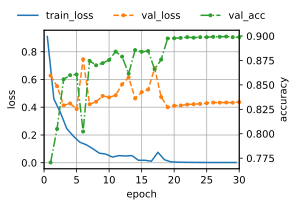

0.8988

In [11]:
data = FashionMNIST10k()
steps_per_epoch = len(data.train_dataloader())  # 79 minibatches of <= 128
model = ClassicRecipe(lr=0.05, num_steps=30 * steps_per_epoch)
trainer = d2l.Trainer(max_epochs=30, num_gpus=1)
trainer.fit(model, data)
trainer.history['val_acc'][-1]

Then the compact modern recipe trains the same network on the same images
for 45 epochs.

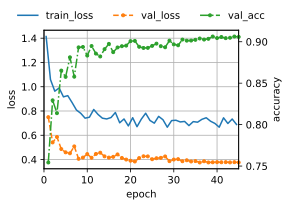

0.9058

In [12]:
model = ModernRecipe(lr=2e-3, num_steps=45 * steps_per_epoch)
trainer = d2l.Trainer(max_epochs=45, num_gpus=1)
trainer.fit(model, data)
trainer.history['val_acc'][-1]

the table collects the test accuracy over repeated runs,
each with its own subset, initialization, and minibatch order.

:The same ResNet-18 under both recipes (10,000 Fashion-MNIST training images at
$96 \times 96$; test accuracy, range over repeated runs).

| Recipe | Epochs | Test accuracy |
|:--|--:|--:|
| A (2015): SGD, warmup, step decay | 30 | 89–90.5% |
| Compact modern: AdamW, cosine, smoothing, Mixup | 45 | 90.5–91% |

The gain is small but consistent. In every pair of runs, the compact modern
recipe beats recipe A trained on the same subset, by half a point to a point
and a half, and its worst run is better than recipe A's best run. On ImageNet
the full recipe adds four points; with 10,000 small grayscale images, a
45-epoch budget, and only part of the menu, the effect is a fraction of that.
The training curves also show why training losses cannot be compared across
recipes. Under the modern recipe the training loss stays far above recipe A's
and even above its own validation loss, because label smoothing and Mixup make
the training targets harder to fit, while the validation loss is the plain
cross-entropy on unmixed test images. The recipes also show that
hyperparameters do not transfer between them: AdamW's base rate is 25 times
smaller than SGD's, so an ablation that swaps one ingredient must retune the
others around it. This is why careful recipe ablations, such as those of
@wightman2021resnet, are expensive.

## Comparing Published Results

The experiment changes how published comparisons should be read. A gain of
a point on ImageNet between two architectures says little unless both were
trained with comparable recipes, since the recipe alone moves a fixed
ResNet-50 by four points. Careful papers therefore retrain their baselines
with their own recipe, and tables that collect numbers from papers of
different years do not support conclusions drawn from one-point gaps.

The test set adds a second source of uncertainty once accuracies are close.
When @Recht.Roelofs.Schmidt.ea.2019 collected a new test set,
ImageNet-V2, by following the original collection protocol
[@Deng.Dong.Socher.ea.2009], models lost 11 to 14 points, yet their
ranking was preserved: gains on the original test set carried over, and the
drop came from a slightly harder distribution of images, not from
overfitting to the old test set. @beyer2020imagenetreal relabeled
the original validation set with multiple labels per image and found that
many apparent errors are ambiguous or multi-object images, and that part of
the recent progress on the original labels comes from fitting their
idiosyncrasies, so one-point gains measured there need not hold under better
labels. For backbones
whose top-1 accuracies lie within a point, differences in transfer, for
example to object detection on COCO or segmentation on ADE20K, are more
informative.

## Summary

Between 2015 and the early 2020s, high-accuracy recipes for convnets changed
along every axis: AdamW or LAMB, cosine decay with warmup, Mixup, CutMix, and
RandAugment, label smoothing, stochastic depth, longer training, and
evaluation of a weight average. On a fixed ResNet-50 they add about four
ImageNet points. Each ingredient takes a few lines: a smoothed target, a
schedule function, a convex combination of two minibatches, a random mask on a
residual branch, and a shadow copy of the parameters. On a ResNet-18 trained
on 10,000 Fashion-MNIST images, a compact subset of the menu gains half a
point to a point and a half over the 2015 recipe in every run. Architecture
comparisons therefore need matched training procedures, and with a fixed
network and budget, tuning the procedure can be cheaper than changing the
architecture. that section starts from the modern recipe and asks
how far a convnet's architecture itself can be modernized.

## Exercises

1. **Binary cross-entropy and Mixup.** @wightman2021resnet train
   with a binary cross-entropy loss that treats each class as an independent
   yes/no target. Explain why this loss pairs naturally with Mixup and
   CutMix. Consider an image that contains parts of two classes,
   and contrast how softmax and sigmoid outputs can represent it.

1. [code] **CutMix.** CutMix [@yun2019cutmix] draws $\lambda$
   uniformly from $[0, 1]$, that is, from $\mathrm{Beta}(1, 1)$ rather than
   the $\mathrm{Beta}(0.2, 0.2)$ the compact modern recipe uses for Mixup.
   It pastes into each image a rectangle from its shuffled partner that
   covers a fraction $1 - \lambda$ of the image area. Implement CutMix as a
   variant of `mixup`, and mix the labels as in the equation with
   $\lambda$ replaced by the fraction of the area actually kept, since a
   rectangle clipped at the image border covers less than $1 - \lambda$.
   Train the compact modern recipe on `FashionMNIST10k` once with CutMix in
   place of Mixup and once with the two alternating at random from
   minibatch to minibatch, as modern recipes do. Compare the test accuracy
   of both runs with the range in the table.

1. [code] **Weight averaging horizon.** Add the `EMA` class to
   `ModernRecipe`: update the shadow copy after every optimizer step, by
   subclassing `d2l.Trainer`, and evaluate with the shadow weights. Sweep
   the decay $\beta$ of the equation over 0.9, 0.99, and 0.999. Count
   the optimizer steps at which `d2l.cosine_warmup` holds the learning rate
   below a tenth of its peak, and relate the best decay to that count
   through the averaging horizon of about $1/(1-\beta)$ steps. Batch
   normalization keeps running statistics that are not parameters; which
   statistics should the averaged model use?

1. [code] **Recipe ablation.** ● In the table the
   compact modern recipe beats recipe A by half a point to a point and a
   half. Whenever a
   configuration below changes the optimizer, retune the learning rate.
    1. Train both recipes on `FashionMNIST10k` five times each and estimate
       the standard deviation of the test accuracy across runs. How large
       must the difference between two configurations be before one run of
       each resolves it?
    1. Starting from the compact modern recipe, replace one ingredient at a
       time by its recipe A counterpart: remove Mixup, remove label
       smoothing, replace the warmup and cosine decay by recipe A's step
       decay, replace AdamW by recipe A's SGD with momentum, and shorten the
       budget from 45 to 30 epochs. Which of the five changes in test
       accuracy exceed the threshold of (a), and do the five add up to the
       total gap?
    1. Train the compact modern recipe with both the optimizer and the
       schedule of recipe A. Together with the compact modern recipe and the
       optimizer and schedule replacements of (b), this run fills a
       $2 \times 2$ table of optimizer against schedule. Do the effects of
       the two ingredients interact?

1. [code] **Weight decay and batch normalization.** ● The training
   refinements collected by @He.Zhang.Zhang.ea.2019 apply weight
   decay (that section) only to the weights of convolutional
   and linear layers and exempt every bias and every scale
   $\boldsymbol{\gamma}$ and shift $\boldsymbol{\beta}$ of batch
   normalization.
    1. When batch statistics are used, the output of batch normalization
       applied to a convolution is unchanged if the convolution's weights
       $\mathbf{W}$ are multiplied by any $c > 0$. What does weight decay on
       $\mathbf{W}$ then do to the loss, to $\|\mathbf{W}\|$ over the course
       of training, and to the effective step size of each gradient update?
    1. Implement both variants, decaying every parameter and decaying only
       the convolutional and linear weights, on `FashionMNIST10k` under the
       compact modern recipe. Compare test accuracy and plot the norms of
       the exempted parameters over training.

    *Adapted from Simon Prince,
    [Understanding Deep Learning](https://udlbook.github.io/udlbook/),
    Problem 11.7.*

1. [code] **Stochastic depth in the recipe.** ● The compact modern recipe
   omits stochastic depth. Add it back.
    1. Extend `StochasticResidual` to the downsampling blocks and build the
       ResNet-18 of that section from it, with the drop probability
       growing linearly from 0 in the first block to $p_{\max}$ in the last.
       What is the expected number of residual branches kept ($b = 1$) for
       one training example, as a function of $p_{\max}$?
    1. Sweep $p_{\max}$ over 0.1, 0.2, and 0.5 on `FashionMNIST10k` under
       the compact modern recipe, which is itself the case $p_{\max} = 0$.
       Does any value raise test accuracy by more than the run-to-run
       spread of the table? How does the best value
       compare with the range of 0.1 to 0.5 used for much deeper networks?
    1. The per-example implementation of `StochasticResidual` computes
       every branch before masking it. Implement the original per-minibatch
       variant of @huang2016stochasticdepth, which draws one $b$ in
       the equation per block and step and skips the branch
       entirely when $b = 0$. Use (a) to predict the fraction of residual
       branches it skips at $p_{\max} = 0.5$. Then measure the fraction of
       training time it saves and compare the two.

[Discussions](https://d2l.discourse.group/t/36761)